In [1]:
# Import the libraries for data work and charts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Hide warnings and set a cleaner plotting style
import warnings
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")


In [4]:
# Load the fraud dataset
df = pd.read_csv("data/AIML Dataset.csv")


In [5]:
# Preview the first rows to confirm the data loaded
df.head()


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [8]:
# Check data types and memory use
df.info() # data types


<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [9]:
# List the columns available in the dataset
df.columns


Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [10]:
# Count how many cases are fraud vs. non-fraud
df["isFraud"].value_counts() # view the fraud split


isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [11]:
# Check whether the flagged-fraud column is also sparse
df["isFlaggedFraud"].value_counts()


isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

In [14]:
# Look for missing values in the dataset
df.isnull().sum().sum() # check for empty values


np.int64(0)

In [15]:
# Confirm the dataset size
df.shape # check rows and columns
# use [0] to get the row count


(6362620, 11)

In [20]:
# Calculate the fraud percentage
round((df["isFraud"].value_counts()[1]/df.shape[0])* 100 ,2) # percentage of fraud
# 0.13% fraud calculation


np.float64(0.13)

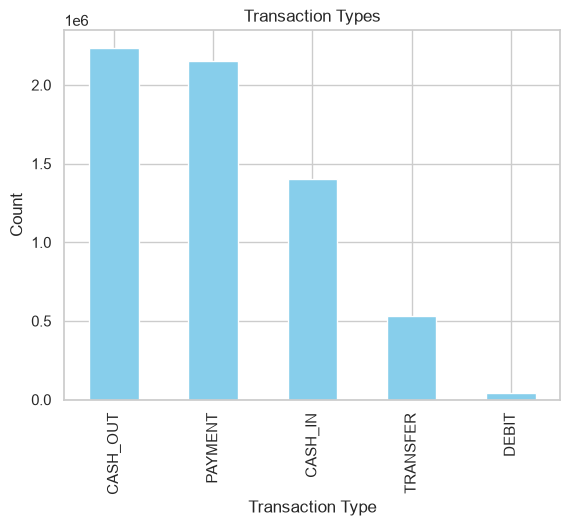

In [22]:
# Plot the transaction types to see the most common ones
df["type"].value_counts().plot(kind="bar", title="Transaction Types", color = "skyblue")
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.show()


In [24]:
# Review the fraud-rate series before plotting
fraud_by_type


type
TRANSFER    0.007688
CASH_OUT    0.001840
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64

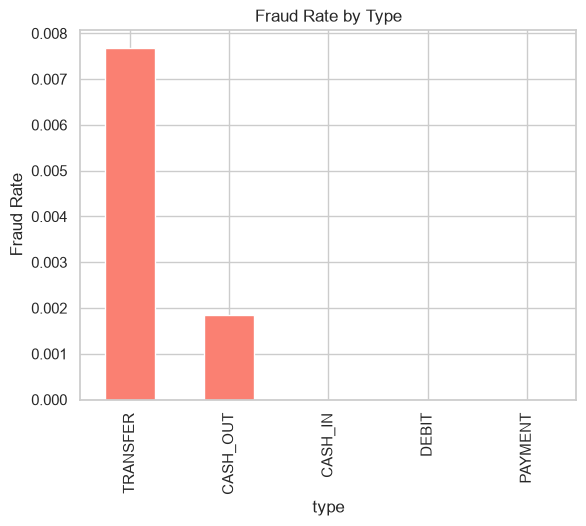

In [23]:
# Compare fraud rate by transaction type
fraud_by_type = df.groupby("type")["isFraud"].mean().sort_values(ascending=False)
fraud_by_type.plot(kind="bar", title="Fraud Rate by Type", color="salmon")
plt.ylabel("Fraud Rate")
plt.show() # shows which type has the highest fraud rate


In [27]:
# Summarize the amount column
df["amount"].describe().astype(int)


count     6362620
mean       179861
std        603858
min             0
25%         13389
50%         74871
75%        208721
max      92445516
Name: amount, dtype: int64

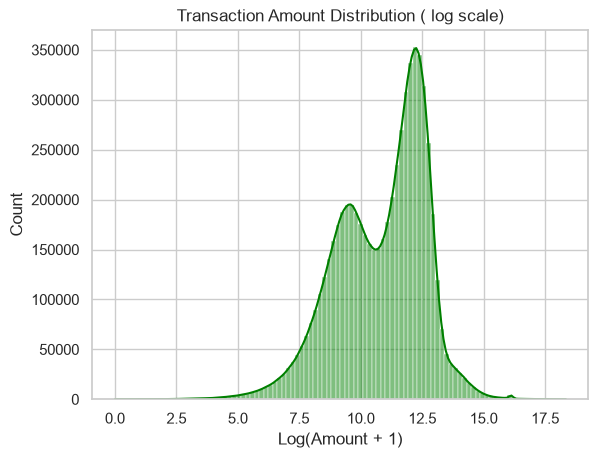

In [30]:
# Inspect the amount distribution on a log scale
sns.histplot(np.log1p(df["amount"]), bins=100, kde =True, color = "green")
plt.title("Transaction Amount Distribution ( log scale)")
plt.xlabel("Log(Amount + 1)")
plt.show()


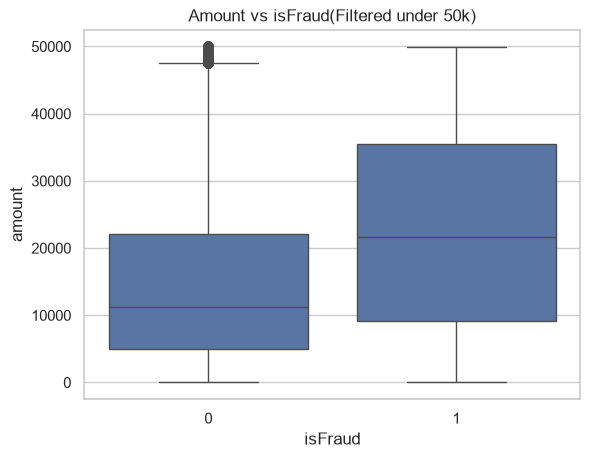

In [32]:
# Compare amount ranges for fraud vs non-fraud
sns.boxplot(data= df[df["amount"] < 50000], x = "isFraud", y ="amount")
plt.title("Amount vs isFraud(Filtered under 50k)")
plt.show()


In [38]:
# Create features to capture balance changes
df["balanceDiffOrig"] = df["oldbalanceOrg"] - df["newbalanceOrig"]
df["balanceDiffDest"] = df["newbalanceDest"] - df["oldbalanceDest"]


In [41]:
# Count suspicious original-balance drops
(df["balanceDiffOrig"] < 0).sum()


np.int64(1399253)

In [42]:
# Count suspicious destination-balance drops
(df["balanceDiffDest"] < 0).sum()


np.int64(1238864)

In [43]:
# Preview the engineered features
df.head(2)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig),balanceDiffDest,balanceDiffOrig
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0,9839.64
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0,1864.28


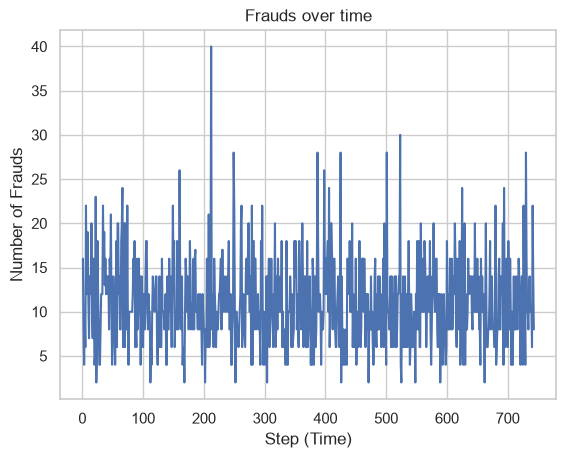

In [47]:
# Plot fraud activity across time steps
frauds_per_step=df[df["isFraud"] == 1]["step"].value_counts().sort_index()
plt.plot(frauds_per_step.index, frauds_per_step.values, label="Frauds per Step")
plt.xlabel("Step (Time)")
plt.ylabel("Number of Frauds")
plt.title("Frauds over time")
plt.grid(True)
plt.show()


In [48]:
# Drop the time column before modeling
df.drop(columns="step", inplace = True)


In [ ]:
# Confirm the feature set is ready for modeling
df.head() # checking if step was removed


,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig),balanceDiffDest,balanceDiffOrig
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0,9839.64
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0,1864.28
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0,181.00
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,-21182.0,181.00
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0,11668.14
